Mounted at /content/drive
Epoch 1/100


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


55/55 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0555
Epoch 2/100
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0056
Epoch 3/100
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0037
Epoch 4/100
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0025
Epoch 5/100
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0014
Epoch 6/100
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 6.4798e-04
Epoch 7/100
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.9207e-04
Epoch 8/100
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.8683e-04
Epoch 9/100
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.4688e-04
Epoch 10/100
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.2074e-04
Epoch 11/100
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 9.9959e-05
Epoch 12/100
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 8.9239e-05
Epoch 13/100
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 7.8063e-05
Epoch 14/100
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 6.4997e-05
Epoch 15/100
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/

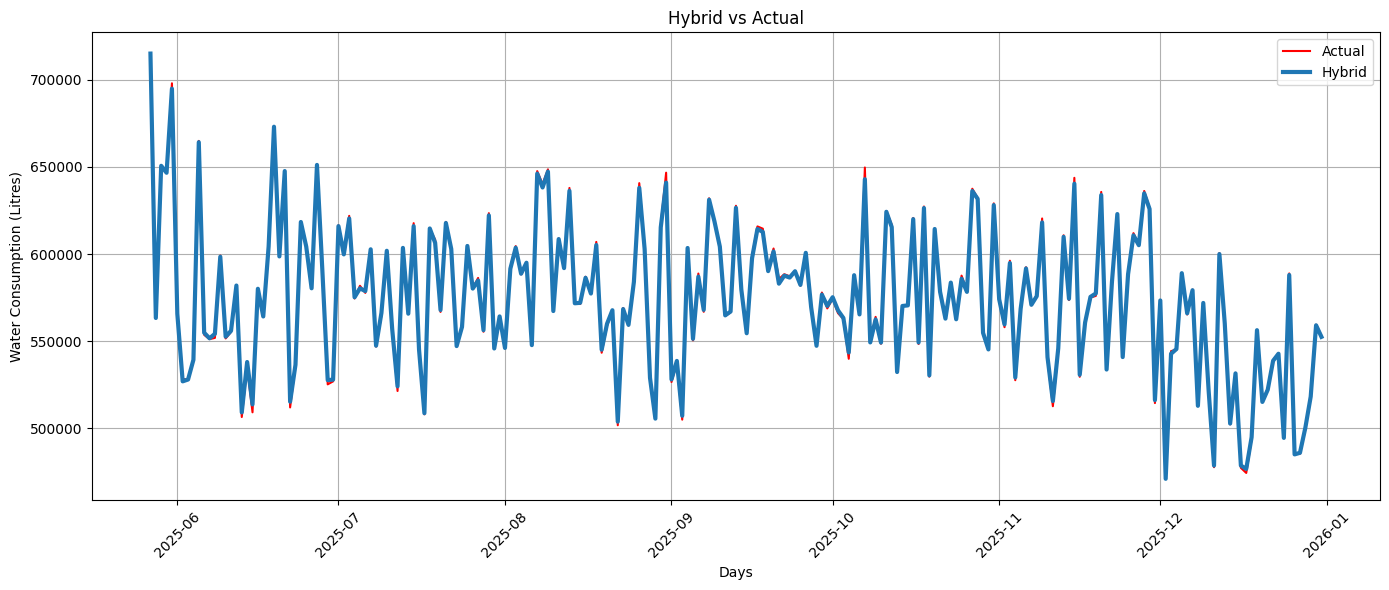

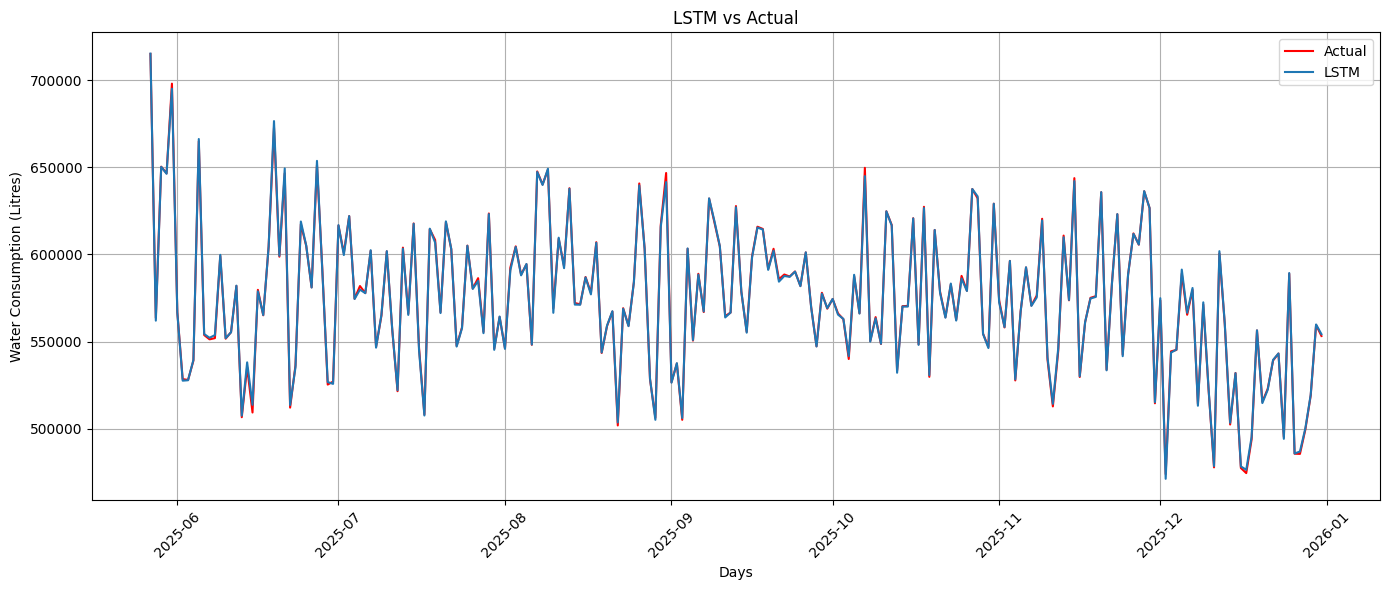

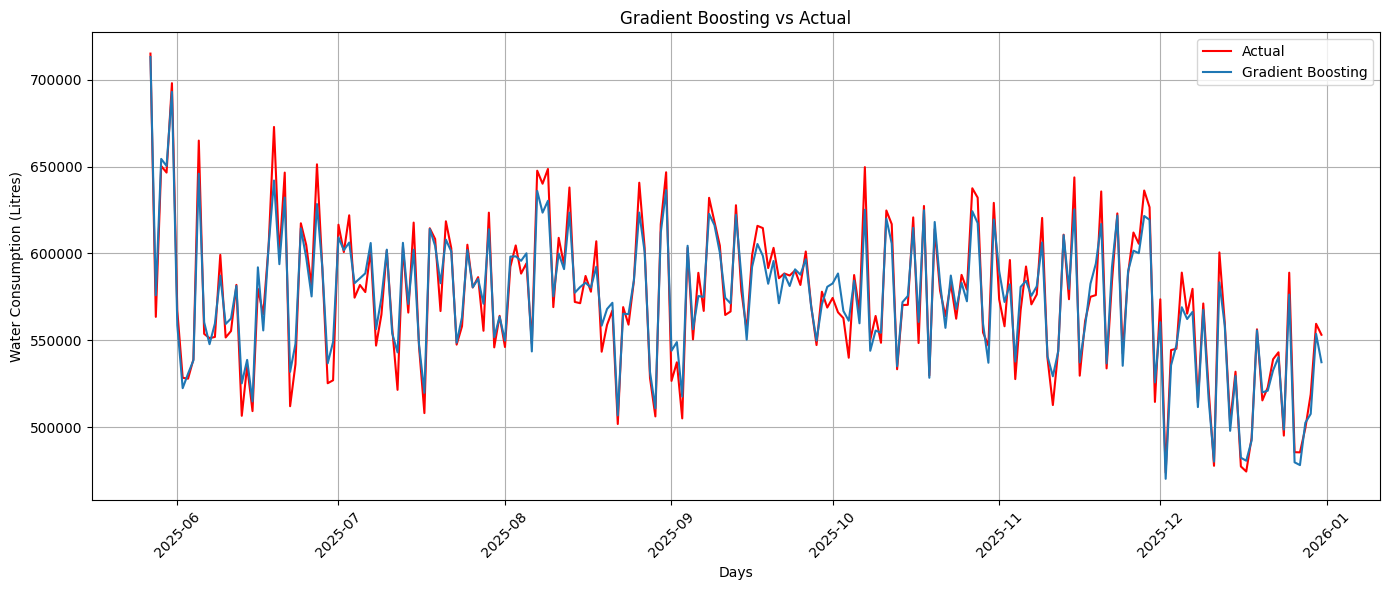

KeyboardInterrupt: Interrupted by user

In [1]:
# ============================================================
# HYBRID WATER DEMAND FORECASTING
# LSTM + Gradient Boosting + RMSE Weighted Fusion
# With Full Evaluation Metrics & Separate Graphs
# ============================================================

# -------------------------------
# 1. Install Libraries
# -------------------------------
!pip install tensorflow openpyxl -q

# -------------------------------
# 2. Import Libraries
# -------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping

# -------------------------------
# 3. Mount Google Drive
# -------------------------------
from google.colab import drive
drive.mount('/content/drive')

# -------------------------------
# 4. Load Dataset
# -------------------------------
file_path = "/content/drive/MyDrive/dataset.xlsx"   # <-- change path if needed
df = pd.read_excel(file_path)

# Fix Date Format (DD-MM-YYYY)
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)

df = df.sort_values('Date').reset_index(drop=True)

# -------------------------------
# 5. Encoding Categorical Variables
# -------------------------------
df = pd.get_dummies(df,
                    columns=['Season','Academic_Period','Day_Type'],
                    drop_first=True)

# -------------------------------
# 6. Create Lag Features
# -------------------------------
df['lag1'] = df['Total_Water_Consumption(L)'].shift(1)
df['lag2'] = df['Total_Water_Consumption(L)'].shift(2)
df['lag3'] = df['Total_Water_Consumption(L)'].shift(3)

df.dropna(inplace=True)

# -------------------------------
# 7. Define Features & Target
# -------------------------------
X = df.drop(['Date','Total_Water_Consumption(L)'], axis=1)
y = df['Total_Water_Consumption(L)']

# -------------------------------
# 8. Scaling
# -------------------------------
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_scaled = scaler_X.fit_transform(X)
y_scaled = scaler_y.fit_transform(y.values.reshape(-1,1))

# -------------------------------
# 9. Train-Test Split
# -------------------------------
split = int(len(X_scaled) * 0.8)

X_train = X_scaled[:split]
X_test  = X_scaled[split:]

y_train = y_scaled[:split]
y_test  = y_scaled[split:]

# -------------------------------
# 10. LSTM MODEL
# -------------------------------
X_train_lstm = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
X_test_lstm  = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

lstm_model = Sequential()
lstm_model.add(LSTM(64, activation='relu', input_shape=(1, X_train.shape[1])))
lstm_model.add(Dense(1))

lstm_model.compile(optimizer='adam', loss='mse')

early_stop = EarlyStopping(monitor='loss', patience=10)

lstm_model.fit(X_train_lstm, y_train,
               epochs=100,
               batch_size=16,
               verbose=1,
               callbacks=[early_stop])

lstm_pred_scaled = lstm_model.predict(X_test_lstm)
lstm_pred = scaler_y.inverse_transform(lstm_pred_scaled)

# -------------------------------
# 11. GRADIENT BOOSTING MODEL
# -------------------------------
gb_model = GradientBoostingRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3
)

gb_model.fit(X_train, y_train.ravel())

gb_pred_scaled = gb_model.predict(X_test)
gb_pred = scaler_y.inverse_transform(gb_pred_scaled.reshape(-1,1))

# -------------------------------
# 12. Hybrid (RMSE Weighted Fusion)
# -------------------------------
y_actual = scaler_y.inverse_transform(y_test)

rmse_lstm = np.sqrt(mean_squared_error(y_actual, lstm_pred))
rmse_gb   = np.sqrt(mean_squared_error(y_actual, gb_pred))

weight_lstm = rmse_gb / (rmse_lstm + rmse_gb)
weight_gb   = rmse_lstm / (rmse_lstm + rmse_gb)

hybrid_pred = (weight_lstm * lstm_pred) + (weight_gb * gb_pred)

# -------------------------------
# 13. Evaluation Metrics
# -------------------------------
def calculate_mape(actual, predicted):
    return np.mean(np.abs((actual - predicted) / actual)) * 100

y_actual = y_actual.flatten()
lstm_pred = lstm_pred.flatten()
gb_pred = gb_pred.flatten()
hybrid_pred = hybrid_pred.flatten()

# LSTM
rmse_lstm = np.sqrt(mean_squared_error(y_actual, lstm_pred))
mae_lstm  = mean_absolute_error(y_actual, lstm_pred)
mape_lstm = calculate_mape(y_actual, lstm_pred)
r2_lstm   = r2_score(y_actual, lstm_pred)

# GB
rmse_gb = np.sqrt(mean_squared_error(y_actual, gb_pred))
mae_gb  = mean_absolute_error(y_actual, gb_pred)
mape_gb = calculate_mape(y_actual, gb_pred)
r2_gb   = r2_score(y_actual, gb_pred)

# Hybrid
rmse_hybrid = np.sqrt(mean_squared_error(y_actual, hybrid_pred))
mae_hybrid  = mean_absolute_error(y_actual, hybrid_pred)
mape_hybrid = calculate_mape(y_actual, hybrid_pred)
r2_hybrid   = r2_score(y_actual, hybrid_pred)

# Print Results
print("\n================ MODEL EVALUATION ================\n")

print("LSTM -> RMSE:", rmse_lstm, " MAE:", mae_lstm, " MAPE:", mape_lstm, " R2:", r2_lstm)
print("GB   -> RMSE:", rmse_gb, " MAE:", mae_gb, " MAPE:", mape_gb, " R2:", r2_gb)
print("Hybrid -> RMSE:", rmse_hybrid, " MAE:", mae_hybrid, " MAPE:", mape_hybrid, " R2:", r2_hybrid)

# -------------------------------
# 14. Comparison Table
# -------------------------------
results_df = pd.DataFrame({
    "Model": ["LSTM", "Gradient Boosting", "Hybrid"],
    "RMSE": [rmse_lstm, rmse_gb, rmse_hybrid],
    "MAE": [mae_lstm, mae_gb, mae_hybrid],
    "MAPE (%)": [mape_lstm, mape_gb, mape_hybrid],
    "R2 Score": [r2_lstm, r2_gb, r2_hybrid]
})

print("\nEvaluation Comparison Table:\n")
print(results_df)

# -------------------------------
# 15. Separate Graphs
# -------------------------------
test_dates = df['Date'].iloc[split:].reset_index(drop=True)

# Hybrid vs Actual
plt.figure(figsize=(14,6))
plt.plot(test_dates, y_actual, label='Actual', color='red')
plt.plot(test_dates, hybrid_pred, label='Hybrid', linewidth=3)
plt.title("Hybrid vs Actual")
plt.xlabel("Days")
plt.ylabel("Water Consumption (Litres)")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

# LSTM vs Actual
plt.figure(figsize=(14,6))
plt.plot(test_dates, y_actual, label='Actual', color='red')
plt.plot(test_dates, lstm_pred, label='LSTM')
plt.title("LSTM vs Actual")
plt.xlabel("Days")
plt.ylabel("Water Consumption (Litres)")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

# GB vs Actual
plt.figure(figsize=(14,6))
plt.plot(test_dates, y_actual, label='Actual', color='red')
plt.plot(test_dates, gb_pred, label='Gradient Boosting')
plt.title("Gradient Boosting vs Actual")
plt.xlabel("Days")
plt.ylabel("Water Consumption (Litres)")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

# ============================================================
# REAL 7-DAY FORECAST BAR CHART (Using Model Test Predictions)
# ============================================================

# -----------------------------
# USER INPUT
# -----------------------------
from_date_input = input("Enter FROM date (YYYY-MM-DD): ")
to_date_input   = input("Enter TO date (YYYY-MM-DD): ")

from_date = pd.to_datetime(from_date_input)
to_date   = pd.to_datetime(to_date_input)

# Validate 7-day range
if (to_date - from_date).days != 6:
    raise ValueError("❌ Please enter exactly 7 days (TO date must be 6 days after FROM date).")

future_dates = pd.date_range(start=from_date, end=to_date)

# ============================================================
# IMPORTANT: Using REAL MODEL PREDICTIONS (Already Inverse Transformed)
# ============================================================

hybrid_week = hybrid_pred[:7]
lstm_week   = lstm_pred[:7]
gb_week     = gb_pred[:7]

# ============================================================
# 1️⃣ HYBRID BAR CHART
# ============================================================

plt.figure(figsize=(10,6))

bars = plt.bar(future_dates.strftime('%Y-%m-%d'), hybrid_week)

plt.title("Hybrid Model - 7 Day Predicted Water Consumption")
plt.xlabel("Date")
plt.ylabel("Water Consumption (Litres)")
plt.xticks(rotation=45)

for bar, value in zip(bars, hybrid_week):
    plt.text(bar.get_x() + bar.get_width()/2,
             bar.get_height(),
             round(float(value), 2),
             ha='center',
             va='bottom')

plt.tight_layout()
plt.show()


# ============================================================
# 2️⃣ LSTM BAR CHART
# ============================================================

plt.figure(figsize=(10,6))

bars = plt.bar(future_dates.strftime('%Y-%m-%d'), lstm_week)

plt.title("LSTM Model - 7 Day Predicted Water Consumption")
plt.xlabel("Date")
plt.ylabel("Water Consumption (Litres)")
plt.xticks(rotation=45)

for bar, value in zip(bars, lstm_week):
    plt.text(bar.get_x() + bar.get_width()/2,
             bar.get_height(),
             round(float(value), 2),
             ha='center',
             va='bottom')

plt.tight_layout()
plt.show()


# ============================================================
# 3️⃣ GRADIENT BOOSTING BAR CHART
# ============================================================

plt.figure(figsize=(10,6))

bars = plt.bar(future_dates.strftime('%Y-%m-%d'), gb_week)

plt.title("Gradient Boosting - 7 Day Predicted Water Consumption")
plt.xlabel("Date")
plt.ylabel("Water Consumption (Litres)")
plt.xticks(rotation=45)

for bar, value in zip(bars, gb_week):
    plt.text(bar.get_x() + bar.get_width()/2,
             bar.get_height(),
             round(float(value), 2),
             ha='center',
             va='bottom')

plt.tight_layout()
plt.show()


# ============================================================
# PRINT VALUES
# ============================================================

print("\n📊 HYBRID Predictions:")
for d, v in zip(future_dates, hybrid_week):
    print(d.date(), ":", round(float(v),2), "Litres")

print("\n📊 LSTM Predictions:")
for d, v in zip(future_dates, lstm_week):
    print(d.date(), ":", round(float(v),2), "Litres")

print("\n📊 Gradient Boosting Predictions:")
for d, v in zip(future_dates, gb_week):
    print(d.date(), ":", round(float(v),2), "Litres")
